# 07 · 真实手写数据：建立测试基准

**目的。**到 notebook 06 为止，所有测试集都是我们自己合成的。这一本把两个**真实**的在线手写数字数据集整理成和游戏完全一致的输入，作为后续实验（08–12）的测试基准。

**为什么需要。**合成数据只能告诉我们"在我们想到的写法上表现如何"。真实数据才能告诉我们"在真实书写者身上表现如何"。详见 `07_literature_and_proposal.md` 第 3 节。

**书写工具是一个独立的变量。**同一个人用笔、手指、鼠标写出来的字并不相同。比如带钩的"1"，用笔或手指写时可能出现，用鼠标写时就未必。所以每个样本都记下书写工具，后面的结果都**按工具分开报告**：

| 工具 | 数据来源 | 本 notebook 是否有 |
|---|---|---|
| 触控笔（数位板） | UCI Pendigits [6] | 有 |
| 手指（手机） | Corr 等人 [7] | 有 |
| 鼠标 | 没有公开数据集，只能自己采集（`collect/index.html`） | 目前没有 |

**本 notebook 的步骤。**

1. 读取 Pendigits 的原始轨迹（UNIPEN 格式）。
2. 读取 Corr 数据集（iPhone，手指书写）。
3. 读取我们自己采集的样本（如果有）。
4. 逐个数字比较不同书写工具的笔画特征。
5. 用**游戏上线版的笔和预处理**把所有轨迹画成 28×28 的图。
6. 逐个数字比较真实写法和 MNIST 写法的差别：哪些数字离 MNIST 最远。
7. **按书写者**划分数据集，并保存。

**约定。**按 3.4 节的决定，Corr 数据集**只用于评估**，不参与训练要上线的模型。

In [1]:
import json, pickle, sys
from collections import Counter
from multiprocessing import Pool
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fingermath import ship                              # the shipped pipeline: pen 18 px, 'area' resampling
from fingermath import datasets                          # MNIST and the collect/ samples

RAW = Path('../cache/raw')                  # downloaded data (git ignores cache/)
REAL = Path('../cache/real'); REAL.mkdir(parents=True, exist_ok=True)
RESULTS = Path('../results')
SEED = 7
plt.rcParams['figure.dpi'] = 110

## 1. 数据来源与许可

| 数据集 | 来源 | 许可 | 本研究中的用途 |
|---|---|---|---|
| Pendigits（原始轨迹 `pendigits-orig.tra/.tes`） | https://archive.ics.uci.edu/dataset/81 | CC BY 4.0 | 训练和测试 |
| Corr 等人的 iPhone 手写数字 | https://github.com/PhilipCorr/numeral-gesture-dataset | 未声明许可，只要求引用 [7] | **只用于测试** |

下载方式（已下载到 `cache/raw/`）：

```bash
# Pendigits：UNIX compress 格式，用 gzip -d 解压
curl -O https://archive.ics.uci.edu/ml/machine-learning-databases/pendigits/pendigits-orig.tra.Z
curl -O https://archive.ics.uci.edu/ml/machine-learning-databases/pendigits/pendigits-orig.tes.Z
gzip -dk pendigits-orig.tra.Z pendigits-orig.tes.Z
# Corr：仓库里的 4 个 CSV（Core Data 导出的表）
curl -O https://raw.githubusercontent.com/PhilipCorr/numeral-gesture-dataset/master/{glyph,stroke,touch,subject}.csv
```

## 2. Pendigits：数位板 + 触控笔

44 位书写者在 WACOM 数位板上用触控笔书写，每人约 250 个数字。官方划分：30 人用于训练（`.tra`），另外 14 人用于"书写者独立"测试（`.tes`），两组没有重叠。

文件是 UNIPEN 格式。每个数字以 `.SEGMENT` 开头，`.COMMENT` 的三个数依次是：标签、书写者编号、序号；每一笔在 `.PEN_DOWN` 和 `.PEN_UP` 之间，每行一个 (x, y) 点。

In [2]:
def parse_unipen(path, prefix):
    """Pendigits UNIPEN file -> list of {label, writer, strokes}; one dict per digit."""
    samples, stroke = [], None
    for line in open(path, encoding='ascii'):
        t = line.split()
        if not t:
            continue
        if t[0] == '.SEGMENT':                       # .SEGMENT DIGIT <index> ? "<label>"
            samples.append({'label': int(t[-1].strip('"')), 'strokes': []})
        elif t[0] == '.COMMENT':                     # .COMMENT <label> <writer> <index>
            assert int(t[1]) == samples[-1]['label']
            samples[-1]['writer'] = f'{prefix}{int(t[2]):02d}'
        elif t[0] == '.PEN_DOWN':
            stroke = []
            samples[-1]['strokes'].append(stroke)
        elif t[0] == '.PEN_UP':
            stroke = None
        elif not t[0].startswith('.') and stroke is not None:
            stroke.append((float(t[0]), float(t[1])))
    for s in samples:
        s['strokes'] = [np.array(st) for st in s['strokes'] if st]
    return samples

pd_train = parse_unipen(RAW / 'pendigits/pendigits-orig.tra', 'pd-a')   # 30 writers
pd_test = parse_unipen(RAW / 'pendigits/pendigits-orig.tes', 'pd-b')    # 14 other writers
print('train digits', len(pd_train), 'writers', len({s["writer"] for s in pd_train}))
print('test  digits', len(pd_test), 'writers', len({s["writer"] for s in pd_test}))

train digits 7494 writers 30
test  digits 3498 writers 14


**坐标方向。**数位板的 y 轴是朝上还是朝下，文件里没有说明。游戏符纸的 y 轴朝下。下面把同一批数字按两种方向各画一次，看哪种是正的。

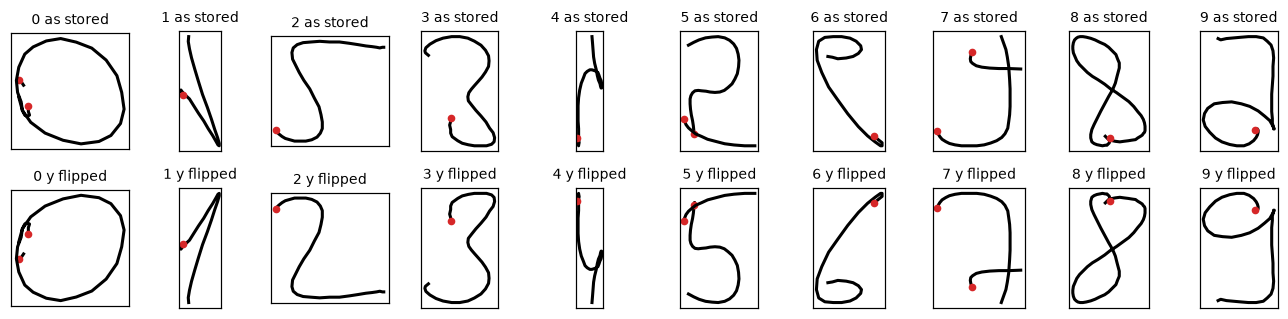

In [3]:
def plot_strokes(ax, strokes, flip=False, title=None):
    for st in strokes:
        y = -st[:, 1] if flip else st[:, 1]
        ax.plot(st[:, 0], y, '-', lw=2, color='k')
        ax.plot(st[0, 0], y[0], 'o', ms=4, color='tab:red')       # where the stroke starts
    ax.invert_yaxis()                                              # y down, like the pad
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    if title is not None:
        ax.set_title(title, fontsize=9)

picks = [next(s for s in pd_train if s['label'] == d) for d in range(10)]
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for i, s in enumerate(picks):
    plot_strokes(axes[0, i], s['strokes'], flip=False, title=f'{s["label"]} as stored')
    plot_strokes(axes[1, i], s['strokes'], flip=True, title=f'{s["label"]} y flipped')
plt.tight_layout(); plt.show()

红点是每一笔的起点。上排（原样）是倒过来的，下排（把 y 取反）是正的，说明数位板的 y 轴朝上。下面统一把 Pendigits 的 y 取反，和游戏一致。

In [4]:
for s in pd_train + pd_test:
    s['strokes'] = [np.column_stack([st[:, 0], -st[:, 1]]) for st in s['strokes']]
    s['device'] = 'pen'
    s['source'] = 'pendigits'

## 3. Corr 等人：iPhone 6，手指

260 位书写者在 iPhone 6 上用手指书写，先用食指、再用拇指，每个数字写多次。数据是 Core Data 导出的四张表：

- `subject`：书写者（年龄、性别、惯用手、母语）
- `glyph`：一个数字（书写者、标签、是否有效、用哪根手指、画布大小）
- `stroke`：一笔（属于哪个数字、第几笔）
- `touch`：一个触点（属于哪一笔、第几个点、时间戳、x、y）

论文作者人工检查过数据，`ZVALID = 0` 的是他们标记为无效的样本，这里去掉。

**数据里的两个坑（第一次解析时踩到，下面的代码已经处理）：**

1. `touch.ZINDEX` 是**整张表的全局序号**，不是点在这一笔里的顺序。按它排序，笔画会变成锯齿状的乱线。点的真实顺序要按时间戳 `ZTIMESTAMP` 排。
2. 时间戳从**每一笔自己开始时**算起（每笔的第一个点都接近 0），所以多笔书写的数字，**笔画之间的先后顺序无法还原**；`stroke.ZINDEX` 也是全局序号，和时间先后只有一半吻合，等于随机。这不影响画成图（画出来的样子和笔画顺序无关），但会影响 notebook 10 的轨迹模型：这个数据集上的多笔数字只能用一个固定的规则排序（比如按笔画的左右位置）。好在多笔书写的只占少数，主要是 4、5、7。

> **更正（notebook 10）：**笔画先后其实可以还原。`stroke.Z_FOK_GLYPH` 是 Core Data 记录的有序关系键，就是真实的笔画顺序（两笔的 7 按它排序，99.9% 是横线在第二笔；按 `ZINDEX` 只有 52%）。上面第 2 条的结论作废；画成图不受影响，notebook 11 的轨迹模型改用 `Z_FOK_GLYPH`。

In [5]:
glyph = pd.read_csv(RAW / 'corr/glyph.csv')
stroke = pd.read_csv(RAW / 'corr/stroke.csv')
touch = pd.read_csv(RAW / 'corr/touch.csv')
subject = pd.read_csv(RAW / 'corr/subject.csv')
print('glyphs', len(glyph), '| valid', int(glyph.ZVALID.sum()), '| strokes', len(stroke), '| touches', len(touch), '| subjects', len(subject))
print(glyph.ZFINGER.value_counts().to_dict(), glyph.ZDEVICE.value_counts().to_dict())

glyphs 20136 | valid 20074 | strokes 24842 | touches 689426 | subjects 257
{'index': 10069, 'thumb': 10067} {'iPhone6 A1586 iOS10.2.1': 20136}


In [6]:
glyph = glyph[glyph.ZVALID == 1]
touch = touch.sort_values(['ZSTROKE', 'ZTIMESTAMP'])      # ZINDEX is a table-wide id, not the order
stroke = stroke.sort_values(['ZGLYPH', 'ZINDEX'])          # order between strokes is unknown (see above)
pts_of = {k: g[['ZX', 'ZY']].to_numpy(float) for k, g in touch.groupby('ZSTROKE')}
time_of = {k: g['ZTIMESTAMP'].to_numpy(float) for k, g in touch.groupby('ZSTROKE')}
strokes_of = {k: list(g['Z_PK']) for k, g in stroke.groupby('ZGLYPH')}
hand_of = dict(zip(subject.Z_PK, subject.ZHANDEDNESS))

corr = []
for r in glyph.itertuples():
    ids = [i for i in strokes_of.get(r.Z_PK, []) if i in pts_of]
    if not ids:
        continue
    corr.append({
        'label': int(r.ZCHARACTER), 'writer': f'co{int(r.ZSUBJECT):03d}',
        'strokes': [pts_of[i] for i in ids], 'times': [time_of[i] for i in ids],
        'finger': r.ZFINGER, 'hand': hand_of.get(r.ZSUBJECT, '?'),
        'pad': (float(r.ZCLIENTWIDTH), float(r.ZCLIENTHEIGHT)),
        'device': 'finger', 'source': 'corr',
    })
print('digits', len(corr), '| writers', len({s["writer"] for s in corr}))
print('per digit', dict(sorted(Counter(s['label'] for s in corr).items())))
print('finger', dict(Counter(s['finger'] for s in corr)), '| handedness', dict(Counter(s['hand'] for s in corr)))

digits 20074 | writers 253
per digit {0: 2006, 1: 2006, 2: 2011, 3: 2007, 4: 2006, 5: 2002, 6: 2015, 7: 2008, 8: 2004, 9: 2009}
finger {'index': 10033, 'thumb': 10041} | handedness {'right': 17766, 'left': 2308}


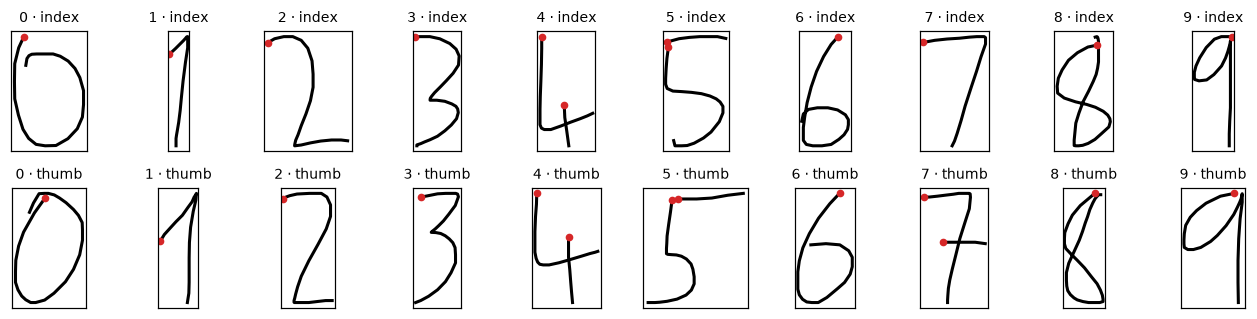

In [7]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for row, finger in enumerate(['index', 'thumb']):
    for d in range(10):
        s = next(s for s in corr if s['label'] == d and s['finger'] == finger)
        plot_strokes(axes[row, d], s['strokes'], title=f'{d} · {finger}')
plt.tight_layout(); plt.show()

iPhone 的坐标和符纸一样是 y 朝下，方向正确，不需要翻转。

## 4. 我们自己采集的样本（鼠标、手指）

`collect/index.html` 采集的样本会存到 `collect/samples/*.json`，每个样本记录了书写工具（`device`）和浏览器报告的指针类型（`pointerType`）。目前目录里只有一个流程自检文件（`writer = pipeline-check`，是程序生成的，不是真人写的），这里把它排除。

In [8]:
own = [s for s in datasets.load_real_samples(single_digit=True) if s['writer'] != 'pipeline-check']
for s in own:
    s['label'] = int(s['label']); s['source'] = 'own'
print('own samples:', len(own), dict(Counter(s['device'] for s in own)))

own samples: 0 {}


## 5. 不同书写工具的笔画特征（每个数字）

先看笔迹本身的几个量，**10 个数字逐个比较**：

- **多笔比例**：用两笔或更多笔写成的比例（比如 4 分两笔、7 加一横、5 的顶上单独一笔）。
- **宽高比**：外框的宽 ÷ 高。
- **弯折度**：笔迹总长 ÷ 外框高度。同一个数字，弯折度高说明多了回笔、钩、圈或装饰笔画。

鼠标的数据目前没有，等自己采集后补上同样的统计。笔迹层面的统计只是第一层；第 7 节会直接在画好的 28×28 图上比较每个数字的写法和 MNIST 有多大差别。

In [9]:
def features(s):
    pts = np.concatenate(s['strokes'])
    w, h = np.ptp(pts[:, 0]), np.ptp(pts[:, 1])
    path = sum(np.linalg.norm(np.diff(st, axis=0), axis=1).sum() for st in s['strokes'])
    return {'source': s['source'], 'device': s['device'], 'label': s['label'],
            'n_strokes': len(s['strokes']), 'n_points': len(pts),
            'aspect': w / max(h, 1e-6), 'bend': path / max(h, 1e-6)}

feat = pd.DataFrame([features(s) for s in pd_train + pd_test + corr + own])
per_digit = {
    'multi-stroke %': (feat.assign(v=feat.n_strokes > 1).pivot_table(index='device', columns='label', values='v') * 100).round(0),
    'median aspect (w/h)': feat.pivot_table(index='device', columns='label', values='aspect', aggfunc='median').round(2),
    'median bend (path/h)': feat.pivot_table(index='device', columns='label', values='bend', aggfunc='median').round(2),
}
for name, t in per_digit.items():
    print(name); print(t); print()

multi-stroke %
label     0     1    2    3     4     5    6     7    8    9
device                                                      
finger  1.0  10.0  0.0  0.0  92.0  51.0  1.0  62.0  2.0  4.0
pen     2.0   5.0  0.0  0.0  60.0  80.0  0.0  86.0  4.0  4.0

median aspect (w/h)
label      0     1     2     3     4     5     6     7     8     9
device                                                            
finger  0.74  0.07  0.72  0.59  0.65  0.64  0.51  0.64  0.55  0.49
pen     0.84  0.46  0.84  0.63  0.55  0.79  0.53  0.65  0.52  0.60

median bend (path/h)
label      0     1     2     3     4     5     6     7     8     9
device                                                            
finger  2.87  1.01  2.40  2.24  1.95  2.29  2.30  1.89  2.93  2.34
pen     3.09  1.85  2.56  2.20  2.00  2.45  2.21  2.15  2.81  2.60



## 6. 画成游戏里的 28×28 输入

每个样本都走**上线版**的流程（`ship.to28`，即 `pad.js` 的渲染加 `processing.js` 的面积平均缩放，笔宽 18）。notebook 06 已经验证过，这个 Python 版本和浏览器里的 JS 在 1000 张图上结果一致。

In [10]:
def render_all(samples):
    with Pool() as pool:
        imgs = pool.starmap(ship.to28, [(s['strokes'], 18, 'area') for s in samples], chunksize=200)
    return np.stack([(np.clip(im, 0, 1) * 255).round().astype(np.uint8) for im in imgs])

x_pd_train, x_pd_test, x_corr = render_all(pd_train), render_all(pd_test), render_all(corr)
x_own = render_all(own) if own else np.zeros((0, 28, 28), np.uint8)
print(x_pd_train.shape, x_pd_test.shape, x_corr.shape, x_own.shape)

(7494, 28, 28) (3498, 28, 28) (20074, 28, 28) (0, 28, 28)


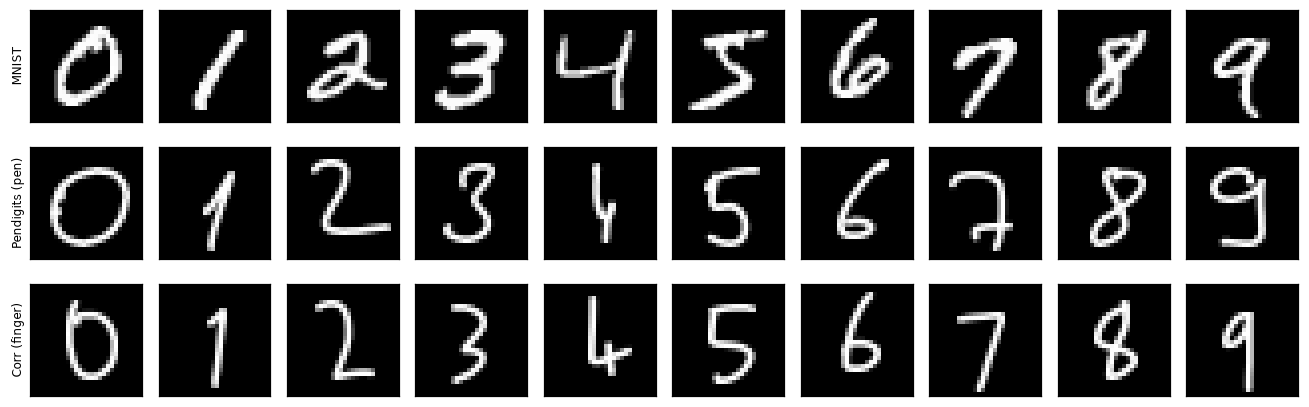

In [11]:
x_mn, y_mn, _, _ = datasets.load_mnist()
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for row, (name, xs, ys) in enumerate([
        ('MNIST', x_mn, y_mn),
        ('Pendigits (pen)', x_pd_train, np.array([s['label'] for s in pd_train])),
        ('Corr (finger)', x_corr, np.array([s['label'] for s in corr]))]):
    for d in range(10):
        ax = axes[row, d]
        ax.imshow(xs[np.flatnonzero(ys == d)[0]], cmap='gray'); ax.set_xticks([]); ax.set_yticks([])
        if d == 0:
            ax.set_ylabel(name, fontsize=8)
plt.tight_layout(); plt.show()

## 7. 每个数字的写法：和 MNIST 比有多大差别

我们的模型主要是在 MNIST 上训练的。一个数字如果在真实书写里常见的写法 MNIST 里很少，模型在这个数字上就容易出错。这一节**对每个数字分别**做：

1. 从 MNIST、触控笔、手指三份数据里，各取同样数量的该数字（每份最多 1000 个，避免 MNIST 数量多而主导结果）。
2. 把 28×28 图像用 PCA 降到 40 维，再用 k-means 聚成 6 类。每一类可以看成这个数字的一种常见写法。
3. 统计每种写法在三份数据里各占多少，画出每类的平均图像。
4. 用**总变差距离**（total variation distance，TVD）衡量两份数据的写法分布差多少：TVD = ½ Σ |p − q|，0 表示写法比例完全相同，1 表示完全不重叠。

注意：这是一个**描述性**的指标，具体数值会随聚类数 k 变化，适合在数字之间比较大小，不适合当成绝对的"差距"。

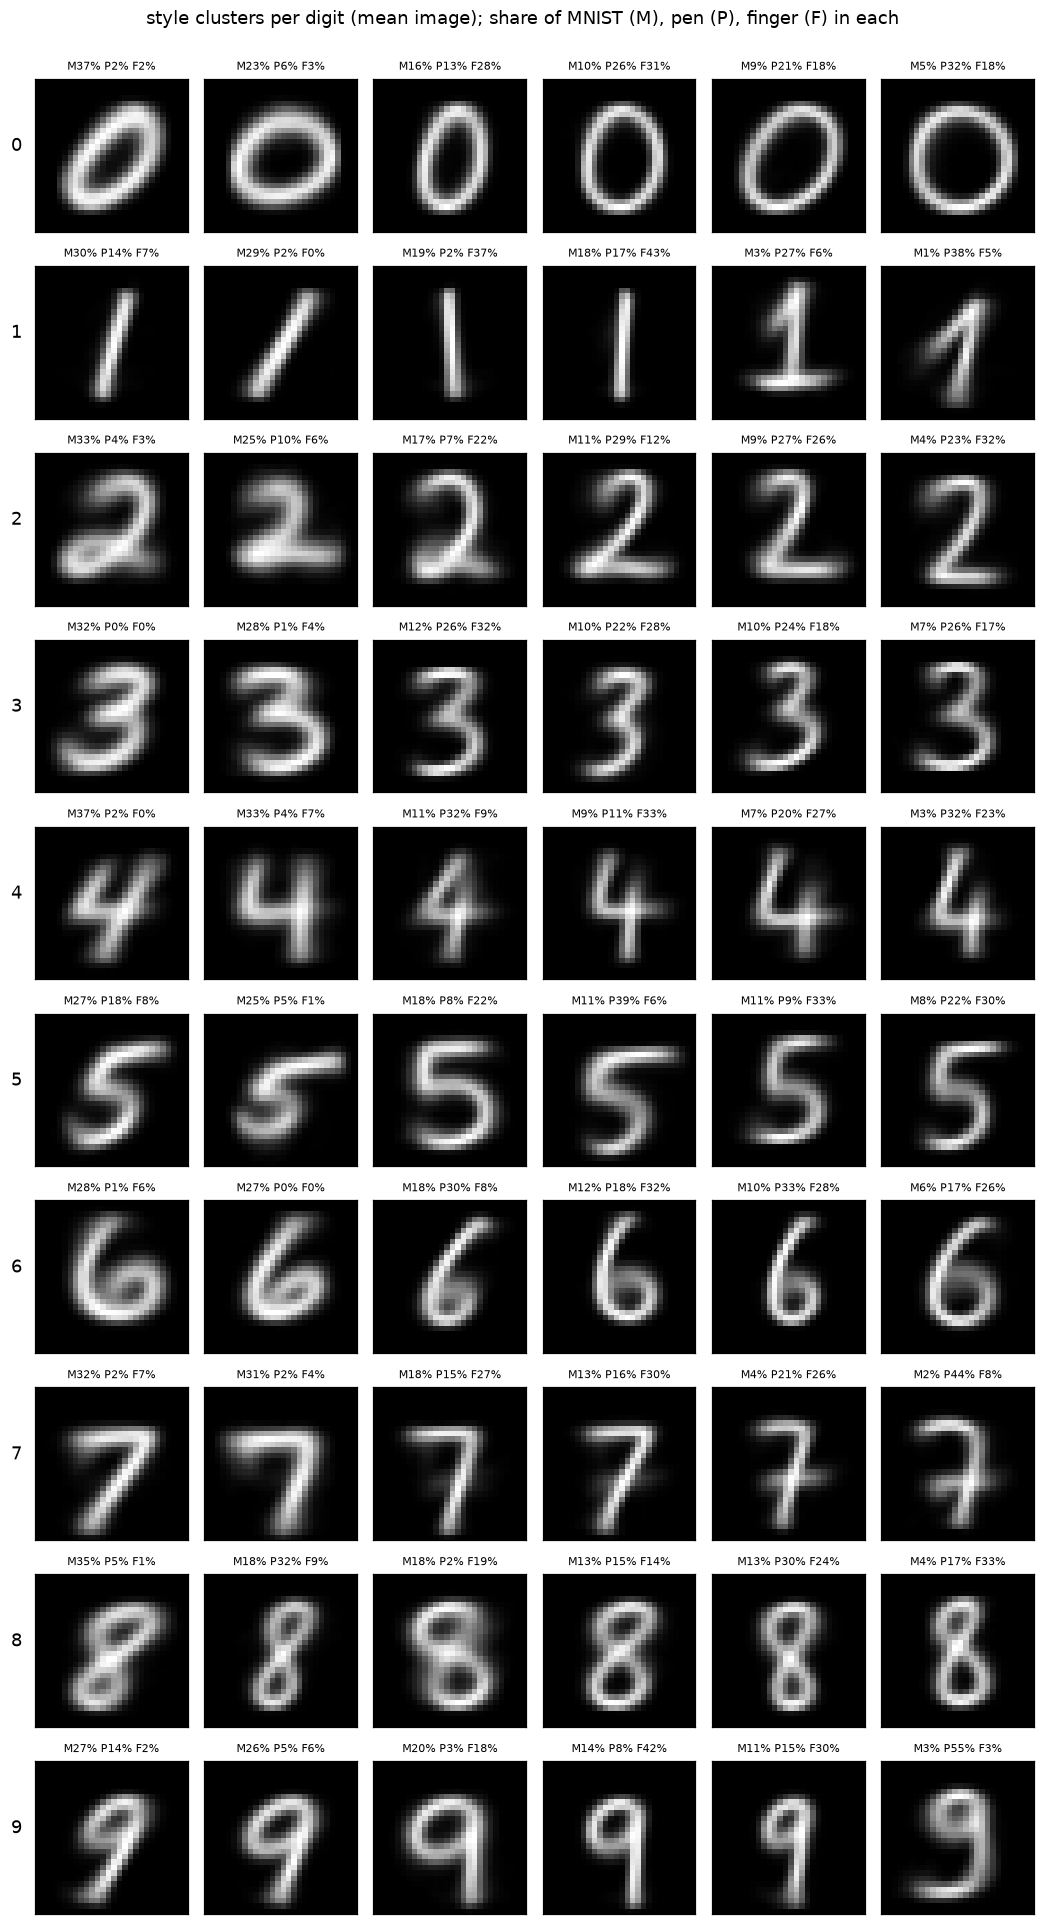

,pen vs MNIST,finger vs MNIST,pen vs finger
digit,,,
0,0.55,0.56,0.20
1,0.61,0.52,0.61
2,0.55,0.50,0.24
3,0.59,0.56,0.15
4,0.64,0.64,0.33
5,0.42,0.47,0.46
6,0.53,0.59,0.28
7,0.61,0.52,0.36
8,0.46,0.43,0.33


In [12]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

K, PER_SOURCE = 6, 1000
y_pd = np.array([s['label'] for s in pd_train + pd_test]); x_pd = np.concatenate([x_pd_train, x_pd_test])
y_co = np.array([s['label'] for s in corr])
sources = {'MNIST': (x_mn, y_mn), 'pen': (x_pd, y_pd), 'finger': (x_corr, y_co)}

styles, gaps = {}, []
fig, axes = plt.subplots(10, K, figsize=(K * 1.6, 10 * 1.75))
for d in range(10):
    rng_d = np.random.default_rng(SEED + d)
    xs, src = [], []
    for name, (x, y) in sources.items():
        idx = np.flatnonzero(y == d)
        idx = rng_d.choice(idx, size=min(PER_SOURCE, len(idx)), replace=False)
        xs.append(x[idx].reshape(len(idx), -1) / 255.0); src += [name] * len(idx)
    xs, src = np.concatenate(xs), np.array(src)
    z = PCA(40, random_state=SEED).fit_transform(xs)
    lab = KMeans(K, n_init=10, random_state=SEED).fit_predict(z)
    share = pd.crosstab(lab, src, normalize='columns')[list(sources)]          # share of each source per style
    order = share['MNIST'].sort_values(ascending=False).index                   # MNIST's most common style first
    styles[d] = share.loc[order]
    for j, c in enumerate(order):
        ax = axes[d, j]
        ax.imshow(xs[lab == c].mean(0).reshape(28, 28), cmap='gray'); ax.set_xticks([]); ax.set_yticks([])
        r = share.loc[c]
        ax.set_title(f'M{r.MNIST:.0%} P{r.pen:.0%} F{r.finger:.0%}', fontsize=7)
        if j == 0:
            ax.set_ylabel(str(d), fontsize=12, rotation=0, labelpad=12)
    tvd = lambda a, b: 0.5 * np.abs(share[a] - share[b]).sum()
    gaps.append({'digit': d, 'pen vs MNIST': tvd('pen', 'MNIST'), 'finger vs MNIST': tvd('finger', 'MNIST'),
                 'pen vs finger': tvd('pen', 'finger')})
fig.suptitle('style clusters per digit (mean image); share of MNIST (M), pen (P), finger (F) in each', y=1.0)
plt.tight_layout(); plt.show()
gap_table = pd.DataFrame(gaps).set_index('digit').round(2)
gap_table

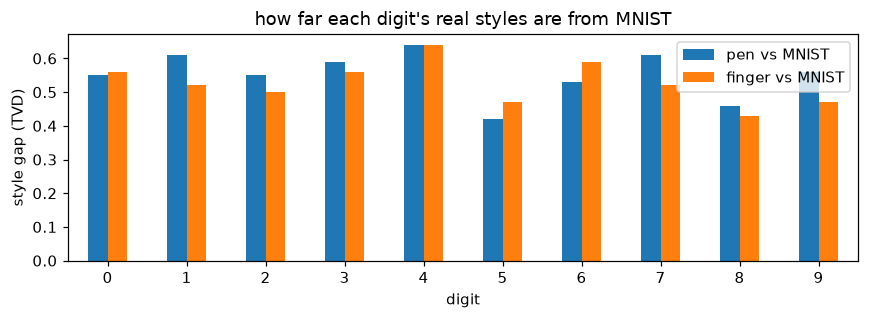

In [13]:
ax = gap_table[['pen vs MNIST', 'finger vs MNIST']].plot.bar(figsize=(8, 3), rot=0)
ax.set_ylabel('style gap (TVD)'); ax.set_title("how far each digit's real styles are from MNIST")
plt.tight_layout(); plt.show()

**这一节的发现。**

1. **所有数字都和 MNIST 有明显差距，不只是"1"。**10 个数字和 MNIST 的写法差距（TVD）都在 0.42–0.64 之间。差距最大的是 **4**（触控笔、手指都是 0.64）、**1**、**7**（触控笔 0.61）和 **3**（0.56–0.59）；最小的是 **5**、**8**（0.42–0.47）。
2. **有一个所有数字共有的差异：倾斜和笔画粗细。**MNIST 最常见的几种写法（每行的前两列）普遍向右倾斜、笔画粗；真实书写的字大多是**直立的、笔画细而均匀**。这是所有数字的公共问题。其中一部分来自"工具"（屏幕上书写往往更直立），一部分来自渲染：真实数据都是用游戏的笔重新画的，笔宽固定，而 MNIST 的笔宽各不相同。所以 TVD 里有一部分反映的是渲染差异，而不全是写法差异。
3. **各个数字也有自己特有的写法，在 MNIST 里很少见：**
   - **1**：带底座的 1（触控笔 27%）、带钩的 1（触控笔 38%）；手指写的大多是一竖，但几乎是竖直的，而 MNIST 的 1 是斜的。
   - **4**：真实数据里的 4 多是两笔交叉写成的，顶端开口、横线穿出竖线；MNIST 的两种主要写法（各占三成多）在真实数据里几乎没有。
   - **7**：中间带横的欧式 7（触控笔两类合计 65%，手指 34%），MNIST 里只有 6%。
   - **9**：竖直尾巴的 9 在触控笔里占 55%（最后一列），MNIST 只有 3%。
   - **0、3、6、8**：真实数据里更窄、更直立。
4. **触控笔和手指之间的差异因数字而异。**0、2、3 两者很接近（TVD 0.15–0.24）；1、9 差异最大（0.61、0.64），5、7 居中。这些差异同时包含"工具"和"人群"两个因素（见第 5 节），要靠我们自己采集同一批人、不同工具的数据才能分开。

**对后续实验的意义：**训练数据需要补上这些真实写法（notebook 09），而且"倾斜和笔宽"这种所有数字共有的差异，可以先用数据增强（随机倾斜、随机笔宽）低成本地试一下。


## 8. 按书写者划分

同一个人的字非常相似，如果同一个人的样本同时出现在训练集和测试集，分数会虚高。所以**一律按书写者划分**：

| 数据集 | 训练 | 验证 | 测试 |
|---|---|---|---|
| Pendigits | 官方训练组 30 人中的 24 人 | 其余 6 人 | 官方测试组 14 人 |
| Corr（只评估） | 无 | 30% 的书写者：`dev`，用来挑方案、调阈值、做校准 | 70% 的书写者：`test`，只在最后报告 |

Corr 分出 `dev` 的原因：notebook 11 要在真实的手指数据上调决策阈值，如果直接在测试集上调，测试集就不再"干净"了。`dev` 只用来调少量决策参数，不用来训练模型的权重。

In [14]:
rng = np.random.default_rng(SEED)
pd_writers = sorted({s['writer'] for s in pd_train})
pd_val_writers = set(rng.choice(pd_writers, size=6, replace=False))
for s in pd_train:
    s['split'] = 'val' if s['writer'] in pd_val_writers else 'train'
for s in pd_test:
    s['split'] = 'test'

co_writers = sorted({s['writer'] for s in corr})
co_dev = set(rng.choice(co_writers, size=round(0.3 * len(co_writers)), replace=False))
for s in corr:
    s['split'] = 'dev' if s['writer'] in co_dev else 'test'
for s in own:
    s['split'] = 'test'

table = pd.DataFrame([{'source': s['source'], 'device': s['device'], 'split': s['split'], 'writer': s['writer']}
                      for s in pd_train + pd_test + corr + own])
summary = table.groupby(['source', 'device', 'split']).agg(digits=('writer', 'size'), writers=('writer', 'nunique'))
summary

digits  writers
source    device split                 
corr      finger dev      6057       76
                 test    14017      177
pendigits pen    test     3498       14
                 train    5998       24
                 val      1496        6

In [15]:
# no writer is in two splits
for src, g in table.groupby('source'):
    per_writer = g.groupby('writer').split.nunique()
    assert (per_writer == 1).all(), src
print('every writer sits in exactly one split')

every writer sits in exactly one split


## 9. 保存

后面的 notebook 直接读这些文件：

- `cache/real/real_digits.npz`：所有样本的 28×28 图像（uint8）和元数据（标签、来源、书写工具、书写者、划分、手指）。
- `cache/real/real_strokes.pkl`：原始笔画（notebook 10 的轨迹模型要用），顺序和上面一致。
- `results/07_datasets.json`：本 notebook 的统计数字。

In [16]:
allx = np.concatenate([x_pd_train, x_pd_test, x_corr, x_own])
alls = pd_train + pd_test + corr + own
meta = {k: np.array([str(s.get(k, '')) for s in alls]) for k in ['source', 'device', 'writer', 'split', 'finger']}
np.savez_compressed(REAL / 'real_digits.npz', x=allx, y=np.array([s['label'] for s in alls]), **meta)
with open(REAL / 'real_strokes.pkl', 'wb') as f:
    pickle.dump([{'strokes': s['strokes'], 'times': s.get('times')} for s in alls], f)

stats = {
    'counts': {f'{a}/{b}/{c}': {'digits': int(r.digits), 'writers': int(r.writers)} for (a, b, c), r in summary.iterrows()},
    'median_strokes_points_aspect': feat.groupby('device')[['n_strokes', 'n_points', 'aspect']].median().round(3).to_dict(),
    'per_digit_strokes': {name: {dev: {str(k): float(v) for k, v in row.items()} for dev, row in t.iterrows()}
                          for name, t in per_digit.items()},
    'style_gap_tvd': {str(d): row.to_dict() for d, row in gap_table.iterrows()},
    'seed': SEED,
}
(RESULTS / '07_datasets.json').write_text(json.dumps(stats, indent=2))
print(json.dumps(stats, indent=2))

{
  "counts": {
    "corr/finger/dev": {
      "digits": 6057,
      "writers": 76
    },
    "corr/finger/test": {
      "digits": 14017,
      "writers": 177
    },
    "pendigits/pen/test": {
      "digits": 3498,
      "writers": 14
    },
    "pendigits/pen/train": {
      "digits": 5998,
      "writers": 24
    },
    "pendigits/pen/val": {
      "digits": 1496,
      "writers": 6
    }
  },
  "median_strokes_points_aspect": {
    "n_strokes": {
      "finger": 1.0,
      "pen": 1.0
    },
    "n_points": {
      "finger": 32.0,
      "pen": 38.0
    },
    "aspect": {
      "finger": 0.59,
      "pen": 0.632
    }
  },
  "per_digit_strokes": {
    "multi-stroke %": {
      "finger": {
        "0": 1.0,
        "1": 10.0,
        "2": 0.0,
        "3": 0.0,
        "4": 92.0,
        "5": 51.0,
        "6": 1.0,
        "7": 62.0,
        "8": 2.0,
        "9": 4.0
      },
      "pen": {
        "0": 2.0,
        "1": 5.0,
        "2": 0.0,
        "3": 0.0,
        "4": 60.0,
 

## 10. 结论与下一步

**得到了什么。**

| 数据 | 工具 | 训练 | 验证 / dev | 测试 |
|---|---|---|---|---|
| Pendigits | 触控笔 | 5,998 个（24 人） | 1,496 个（6 人） | 3,498 个（14 人） |
| Corr | 手指 | 不用于训练 | dev：6,057 个（76 人） | 14,017 个（177 人） |
| 自己采集 | 鼠标 / 手指 | — | — | 0 个（还没有采集） |

所有样本都已经按游戏上线版的流程画成了 28×28 的图，书写者在不同划分之间没有重叠（已检查）。

**数据清洗中发现并修正的问题。**Corr 数据集里，触点的 `ZINDEX` 是整张表的全局序号，不是笔画内的顺序，必须按时间戳排序；多笔数字的笔画先后顺序无法还原（见第 3 节）。

**写法上的结论（第 5、7 节）。**10 个数字的真实写法都和 MNIST 有明显差距，差距最大的是 4、1、7、3。差距包括所有数字共有的部分（真实书写更直立、笔画更细且均匀），也包括各个数字特有的写法（带底座或带钩的 1、交叉写的 4、带横的 7、竖直尾巴的 9）。触控笔和手指之间的差异则因数字而异，而且混有"人群"的因素，需要自己采集的数据才能分开。

**下一步：notebook 08。**用这些真实测试集评估现在上线的 CNN 和旧 MLP：按工具分开的准确率、每个数字的准确率和混淆矩阵、每个书写者的准确率分布、置信度是否可靠，以及在游戏规则下的"接受率"和"打错妖怪率"。逐个数字看错误：哪些数字错得多、被读成了什么，以及第 7 节里离 MNIST 最远的数字（4、1、7、3）是不是真的错得最多。
